# MiniGPT Shakespeare — Demo recording notebook

This notebook is the **recording companion** for the nine required demo checkpoints. It is deliberately artifact-first: it reads the committed logs, figures, samples, and ablation results, so running it does **not** retrain the model. Cells that need a local trained checkpoint are optional and clearly labeled.

## Recording rule

Run the notebook from the repository root or from `notebooks/`. Scroll top-to-bottom and record each numbered section. Keep the code and its output visible. Do not claim that a live checkpoint was loaded unless the optional checkpoint cell reports that it found one.

The nine sections below map directly to the assignment checklist: repository, attention/masking, tests, model specification, loss curves, generation, attention inspection, deployment, and ablations/limitations.

In [4]:
from pathlib import Path
import csv
import json
import subprocess
import sys
import uuid
from collections import defaultdict

import matplotlib.pyplot as plt
import torch

def find_root():
    candidates = [Path.cwd(), *Path.cwd().parents]
    for candidate in candidates:
        if (candidate / "src" / "gpt.py").exists() and (candidate / "outputs").exists():
            return candidate
    raise FileNotFoundError("Run this notebook inside the minigpt-shakespeare repository")

ROOT = find_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print(f"Repository root: {ROOT}")
print(f"Python: {sys.version.split()[0]} | PyTorch: {torch.__version__}")

Repository root: d:\ai_eng_assingment1\minigpt-shakespeare
Python: 3.12.5 | PyTorch: 2.14.1+cpu


## 1. Repository structure

**Say:** “This is a decoder-only, character-level GPT. The model path is `src/gpt.py` → `src/transformer_block.py` → `src/attention.py`. Training, inference, tests, experiments, and saved evidence are separated into their own folders.”

In [5]:
important = [
    "src/gpt.py", "src/attention.py", "src/transformer_block.py",
    "src/train.py", "src/generate.py", "src/api.py", "src/checkpoint.py",
    "tests/", "experiments/", "configs/tiny_gpt.yaml",
    "outputs/logs/tiny_gpt/metrics.jsonl", "outputs/figures/",
    "outputs/ablations/results.csv", "Dockerfile", "render.yaml",
]
for item in important:
    path = ROOT / item
    print(f"{'[OK]' if path.exists() else '[MISSING]'} {item}")

print("\nCore source files:")
for path in sorted((ROOT / "src").glob("*.py")):
    print("  ", path.relative_to(ROOT))

[OK] src/gpt.py
[OK] src/attention.py
[OK] src/transformer_block.py
[OK] src/train.py
[OK] src/generate.py
[OK] src/api.py
[OK] src/checkpoint.py
[OK] tests/
[OK] experiments/
[OK] configs/tiny_gpt.yaml
[OK] outputs/logs/tiny_gpt/metrics.jsonl
[OK] outputs/figures/
[OK] outputs/ablations/results.csv
[OK] Dockerfile
[OK] render.yaml

Core source files:
   src\__init__.py
   src\api.py
   src\attention.py
   src\checkpoint.py
   src\config.py
   src\dataset.py
   src\generate.py
   src\gpt.py
   src\numpy_gpt.py
   src\positional_encoding.py
   src\tokenizer.py
   src\train.py
   src\transformer_block.py
   src\utils.py


## 2. Attention and causal masking

**Say:** “For each query position, attention computes `softmax(QKᵀ / √d + M)V`. The boolean mask is true above the diagonal, so those future scores become negative infinity. After softmax, future-token weights are exactly zero. A token can attend to itself and any earlier token, never to a future token.”

The next cell shows the real implementation’s mask, then verifies the invariant numerically.

In [6]:
from src.attention import causal_mask, scaled_dot_product_attention
T = 8
mask = causal_mask(T)
print("True = blocked future position; False = allowed:")
print(mask)
torch.manual_seed(7)
q = torch.randn(1, 2, T, 4)
k = torch.randn(1, 2, T, 4)
v = torch.randn(1, 2, T, 4)
_, weights = scaled_dot_product_attention(q, k, v, mask=mask)
future_weight = weights.masked_select(mask).abs().max().item()
print(f"\nmaximum attention weight on any future position: {future_weight:.3g}")
assert future_weight == 0.0
print("PASS: causal masking prevents information leakage from future tokens.")

True = blocked future position; False = allowed:
tensor([[False,  True,  True,  True,  True,  True,  True,  True],
        [False, False,  True,  True,  True,  True,  True,  True],
        [False, False, False,  True,  True,  True,  True,  True],
        [False, False, False, False,  True,  True,  True,  True],
        [False, False, False, False, False,  True,  True,  True],
        [False, False, False, False, False, False,  True,  True],
        [False, False, False, False, False, False, False,  True],
        [False, False, False, False, False, False, False, False]])

maximum attention weight on any future position: 0
PASS: causal masking prevents information leakage from future tokens.


## 3. Test suite

**Say:** “The correctness gate is the repository test suite, not just a visual demo. I am running its non-training tests with `python -m pytest`. The overfit test is intentionally skipped because it performs 200 optimizer steps.”

In [18]:
import uuid

# A unique directory avoids Windows permission conflicts with old pytest folders.
pytest_temp = ROOT / f".pytest_tmp_{uuid.uuid4().hex}"
result = subprocess.run(
    [sys.executable, "-m", "pytest", "--ignore=tests/test_overfit.py",
     f"--basetemp={pytest_temp}", "-p", "no:cacheprovider"], cwd=ROOT, text=True,
    capture_output=True,
)
print(result.stdout)
if result.stderr:
    print(result.stderr)
print(f"pytest exit code: {result.returncode}")
if result.returncode != 0:
    raise RuntimeError("The test suite failed; fix or explain this before recording the final demo.")

.................................................................        [100%]
============================== warnings summary ===============================
..\.venv\Lib\site-packages\fastapi\testclient.py:1
  d:\ai_eng_assingment1\.venv\Lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
    from starlette.testclient import TestClient as TestClient  # noqa

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
65 passed, 1 warning in 14.07s

pytest exit code: 0


## 4. Model specification and the 4.77M parameter count

**Say:** “The final model has 6 Transformer blocks, 4 attention heads, width 256, FFN width 1024, context 256, and a 65-character vocabulary. The count is computed from the instantiated model and independently checked by the closed-form formula in `src/gpt.py`.”

In [14]:
from src.config import load_config
from src.gpt import MiniGPT, analytic_parameter_count
cfg = load_config(ROOT / "configs" / "tiny_gpt.yaml")
model = MiniGPT(cfg.model)
actual = model.num_parameters()
analytic = analytic_parameter_count(cfg.model)
print(json.dumps(model.config_dict(), indent=2))
print(f"\ninstantiated trainable parameters: {actual:,} ({actual / 1e6:.2f}M)")
print(f"closed-form analytic count:        {analytic:,}")
print(f"counts agree: {actual == analytic}")
print("\nLargest architectural contribution:")
for name, shape, count in model.parameter_table()[:12]:
    print(f"  {name:35s} {str(shape):18s} {count:,}")
assert actual == analytic == 4_772_352

{
  "vocab_size": 65,
  "context_length": 256,
  "d_model": 256,
  "n_heads": 4,
  "n_layers": 6,
  "ffn_dim": 1024,
  "dropout": 0.2,
  "pos_encoding": "sinusoidal",
  "tie_weights": false,
  "attn_impl": "manual",
  "causal": true,
  "bias": true
}

instantiated trainable parameters: 4,772,352 (4.77M)
closed-form analytic count:        4,772,352
counts agree: True

Largest architectural contribution:
  tok_emb.weight                      (65, 256)          16,640
  blocks.0.ln1.weight                 (256,)             256
  blocks.0.ln1.bias                   (256,)             256
  blocks.0.attn.q_proj.weight         (256, 256)         65,536
  blocks.0.attn.q_proj.bias           (256,)             256
  blocks.0.attn.k_proj.weight         (256, 256)         65,536
  blocks.0.attn.k_proj.bias           (256,)             256
  blocks.0.attn.v_proj.weight         (256, 256)         65,536
  blocks.0.attn.v_proj.bias           (256,)             256
  blocks.0.attn.out_proj.weight  

## 5. Training versus validation loss

**Say:** “This is the saved 3,000-step run, not a newly trained curve. Both losses fall sharply from the character-level baseline. The validation loss reaches its best value, 1.3531, at step 2750 and then is essentially flat/slightly higher, while the final train loss is 1.0652. That gap is evidence of mild overfitting, so the best-validation checkpoint is the one to report.”

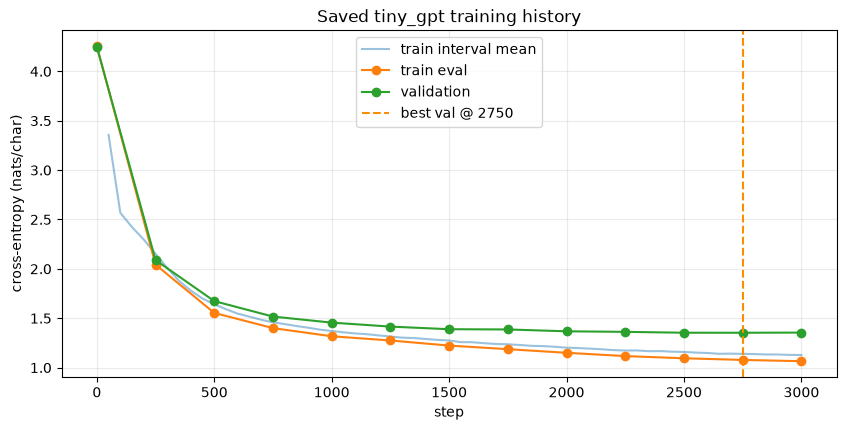

best validation: 1.3531 at step 2750
final train: 1.0652 | final validation: 1.3549 | gap: 0.2897


In [15]:
records = []
with (ROOT / "outputs/logs/tiny_gpt/metrics.jsonl").open(encoding="utf-8") as f:
    records = [json.loads(line) for line in f]
train = [r for r in records if r["event"] == "train"]
evals = [r for r in records if r["event"] == "eval"]
best = min(evals, key=lambda r: r["val_loss"])
last = evals[-1]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot([r["step"] for r in train], [r["train_loss"] for r in train], alpha=.45, label="train interval mean")
ax.plot([r["step"] for r in evals], [r["train_loss"] for r in evals], "o-", label="train eval")
ax.plot([r["step"] for r in evals], [r["val_loss"] for r in evals], "o-", label="validation")
ax.axvline(best["step"], color="darkorange", linestyle="--", label=f"best val @ {best['step']}")
ax.set(xlabel="step", ylabel="cross-entropy (nats/char)", title="Saved tiny_gpt training history")
ax.grid(alpha=.25); ax.legend(); plt.show()
print(f"best validation: {best['val_loss']:.4f} at step {best['step']}")
print(f"final train: {last['train_loss']:.4f} | final validation: {last['val_loss']:.4f} | gap: {last['val_loss'] - last['train_loss']:.4f}")

## 6. Fixed-prompt text generation

**Say:** “For reproducibility I use prompt `ROMEO:`, temperature 0.8, and seed 42. The saved sample below is from the released 4.77M checkpoint. If a checkpoint has been downloaded locally, the optional cell also runs the actual CLI.”

Do not retrain here. A checkpoint is only needed for live generation; the saved output is the evidence when the checkpoint is not present in the clone.

In [11]:
sample_file = ROOT / "outputs/samples/samples.md"
text = sample_file.read_text(encoding="utf-8")
start = text.index("## Prompt 1")
end = text.index("## Prompt 2")
print(text[start:end].strip())

checkpoint_candidates = [ROOT / "checkpoints/minigpt_shakespeare.pt", ROOT / "checkpoints/tiny_gpt/best.pt"]
checkpoint = next((p for p in checkpoint_candidates if p.exists()), None)
print(f"\nLocal checkpoint available: {checkpoint if checkpoint else 'no (saved sample shown above)'}")

## Prompt 1: `'ROMEO:'`

*valid-word rate 0.98, distinct-2 1.00, 4-gram repetition 0.00*

**Sampled (T = 0.8):**

```text
ROMEO:
Far is false; 'tis gone.

MERCUTIO:
Come, you sup your grace is that will conceive
Against me with contrives with the great England.

ROMEO:
That Hermione that we may have proved him within,
Whose canst will we are assured his daughter's mouth?

MERCUTIO:
The case, my lord, the head that send were 
```

**Greedy (T = 0), 120 characters:**

```text
ROMEO:
I will not be so much a man to be a man.

ROMEO:
I will not be so much a man to be a man.

ROMEO:
I will not be so much
```

Local checkpoint available: no (saved sample shown above)


In [12]:
if checkpoint:
    command = [sys.executable, "-m", "src.generate", "--checkpoint", str(checkpoint),
               "--prompt", "ROMEO:", "--max-new-tokens", "120", "--temperature", "0.8", "--seed", "42"]
    live = subprocess.run(command, cwd=ROOT, text=True, capture_output=True)
    print(live.stdout)
    if live.returncode:
        print(live.stderr)
        raise RuntimeError("Live generation failed")
else:
    print("Skipped live CLI: no local checkpoint. Use the recorded CLI command below after downloading it.")
    print("python -m src.generate --prompt \"ROMEO:\" --max-new-tokens 200 --seed 42")

Skipped live CLI: no local checkpoint. Use the recorded CLI command below after downloading it.
python -m src.generate --prompt "ROMEO:" --max-new-tokens 200 --seed 42


## 7. Attention inspection

**Say:** “This is an attention map from the trained model. Rows are query characters and columns are attended-to key characters. The upper triangle is zero because of causal masking. Early heads are often local—for example, attending to the previous character—while deeper heads can distribute mass over longer ranges.”

The figure was generated by `experiments/attention_visualization.py`; the accompanying text gives measured per-head distances and previous-token weights.

fig7_attention_detail.png exists: True


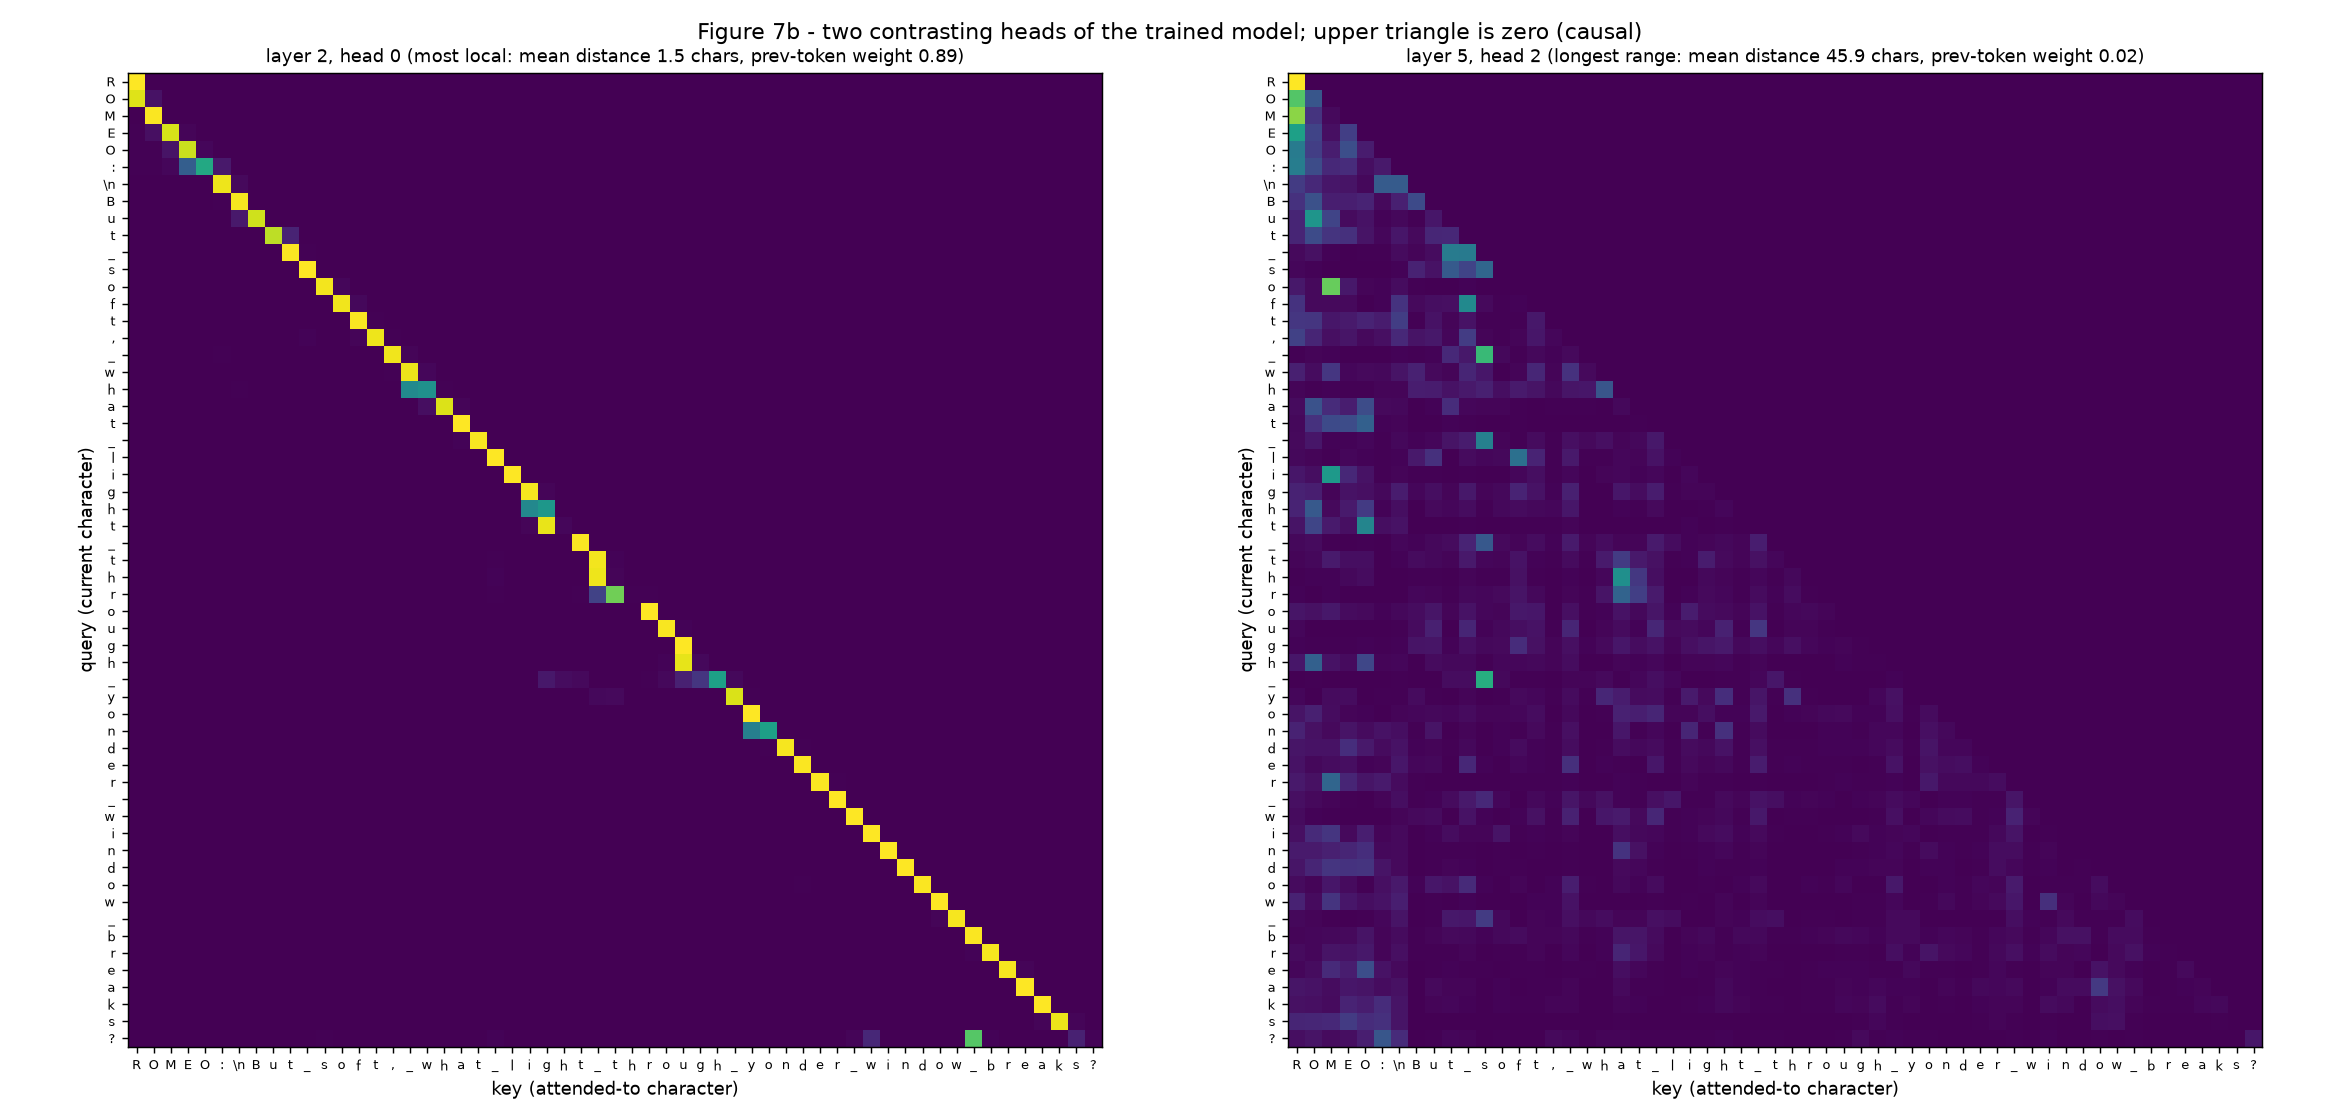

fig7_attention_heads.png exists: True


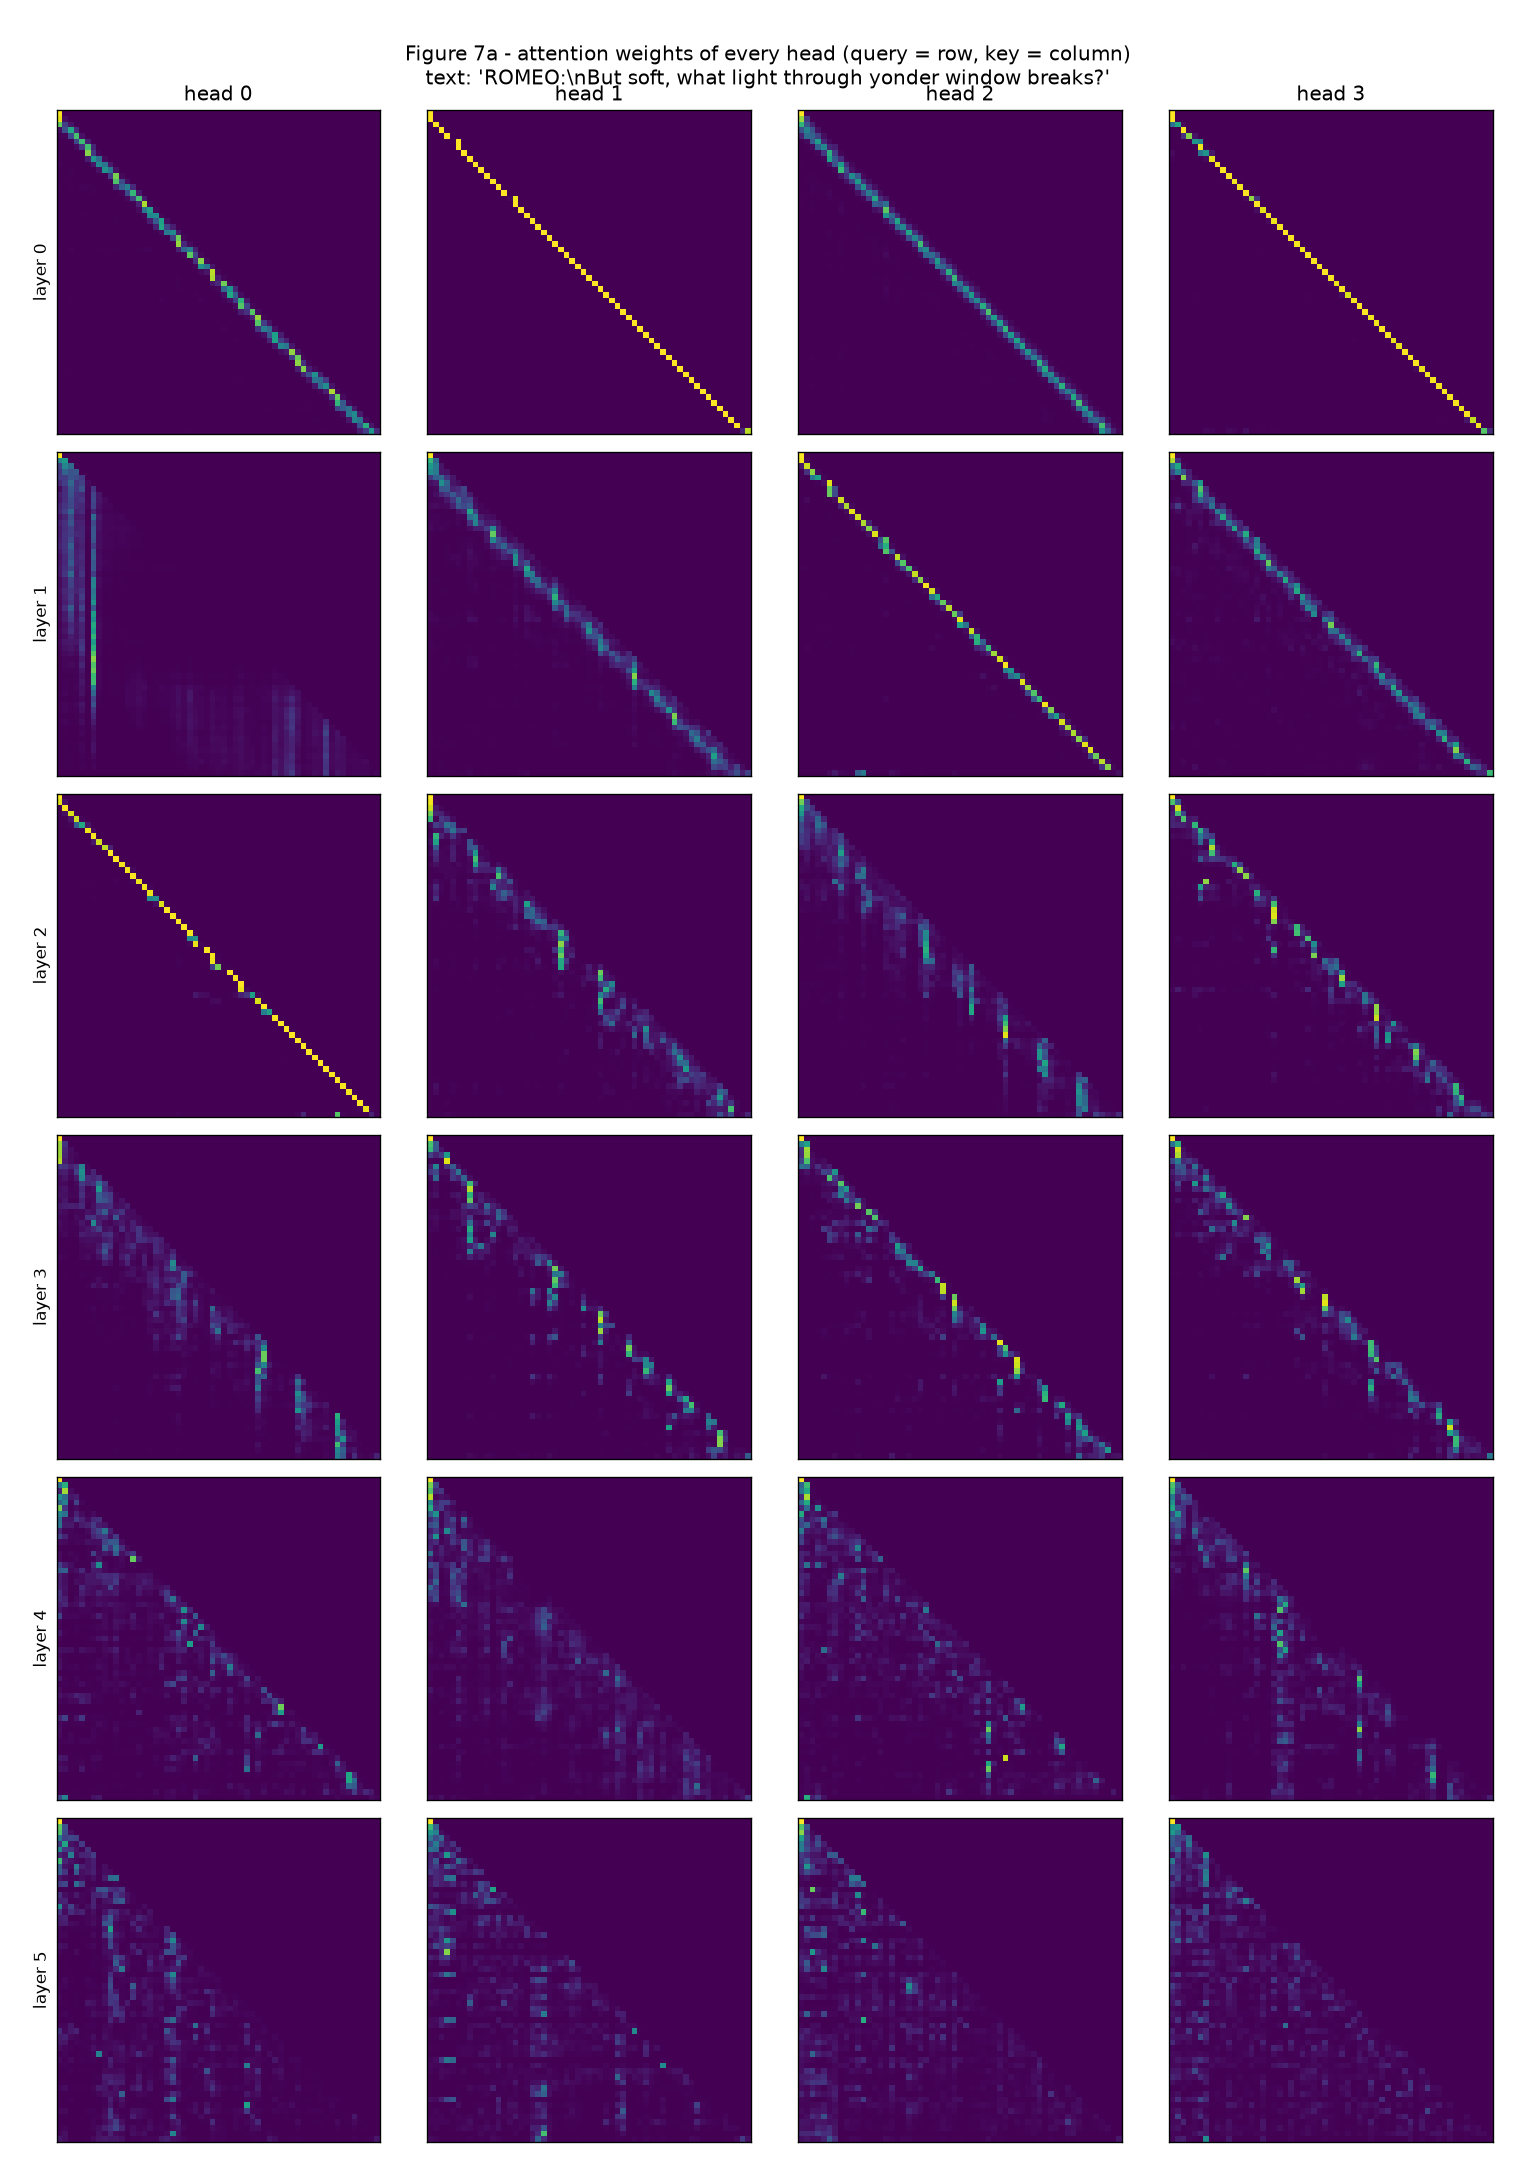

Per-head attention statistics, averaged over 64 validation windows (context 256, query positions >= 16)
  mean_dist  = expected distance (i - j) to the attended key
  prev       = weight on the immediately preceding character
  self       = weight on the current character
  first      = weight on the first position of the window

layer head  mean_dist   prev   self  first
    0    0       3.11   0.47   0.05   0.00
    0    1       1.71   0.93   0.05   0.00
    0    2       3.68   0.14   0.02   0.00
    0    3       3.18   0.92   0.02   0.00
    1    0      17.62   0.03   0.02   0.01
    1    1       7.29   0.08   0.05   0.00
    1    2       7.24   0.74   0.04   0.00
    1    3       9.32   0.21   0.09   0.00
    2    0       1.45   0.89   0.02   0.00
    2    1       7.03   0.17   0.05   0.00
    2    2       8.84   0.07   0.05   0.00
    2    3       5.54   0.26   0.06   0.00
    3    0       9.56   0.08   0.05   0.00
    3    1       7.28   0.21   0.06   0.00
    3    2       7.12  

In [13]:
from IPython.display import Image, display
for filename in ["fig7_attention_detail.png", "fig7_attention_heads.png"]:
    path = ROOT / "outputs/figures" / filename
    print(filename, "exists:", path.exists())
    if path.exists():
        display(Image(filename=str(path), width=900))
print((ROOT / "outputs/figures/fig7_attention_stats.txt").read_text(encoding="utf-8"))

## 8. Deployment and inference

**Say:** “The same model is exposed through FastAPI. The public deployment has `/docs`, `/health`, `/model-info`, and `POST /generate`; the generation endpoint may require an API key. I will first show the public metadata endpoint, then open Swagger docs in a browser.”

For a local recording, run this in a separate terminal before this cell:

```text
uvicorn src.api:app --host 127.0.0.1 --port 8000
```

Then change `API_BASE` to `http://127.0.0.1:8000`. Never put a private API key in this notebook.

In [9]:
import urllib.request
API_BASE = "https://minigpt-shakespeare.containers.snapdeploy.app"
for endpoint in ["/health", "/model-info"]:
    url = API_BASE + endpoint
    try:
        with urllib.request.urlopen(url, timeout=15) as response:
            body = response.read().decode("utf-8")
        print(endpoint, response.status)
        print(json.dumps(json.loads(body), indent=2)[:4000])
    except (OSError, ValueError) as exc:
        print(f"Could not reach {url}: {exc}")
        print("Open the URL manually or use the local uvicorn command above.")

Could not reach https://minigpt-shakespeare.containers.snapdeploy.app/health: HTTP Error 403: Forbidden
Open the URL manually or use the local uvicorn command above.
Could not reach https://minigpt-shakespeare.containers.snapdeploy.app/model-info: HTTP Error 403: Forbidden
Open the URL manually or use the local uvicorn command above.


## 9. Ablations and limitations

**Say:** “This is an actual three-seed ablation, not an unsupported claim. Increasing depth from 2 to 6 layers lowers mean validation loss from about 1.630 to 1.495, at the cost of more parameters and slower steps. Removing positional encoding is worse than sinusoidal encoding. The main limitations are character-level output quality, a small single-domain corpus, mild train/validation overfitting, and no KV cache for fast long-form generation.”

depth    2 layers       best val loss 1.6301 +/- 0.0040 (n=3)
depth    4 layers       best val loss 1.5327 +/- 0.0009 (n=3)
depth    6 layers       best val loss 1.4947 +/- 0.0045 (n=3)
position sinusoidal     best val loss 1.5327 +/- 0.0009 (n=3)
position learned        best val loss 1.5514 +/- 0.0039 (n=3)
position none           best val loss 1.7200 +/- 0.0046 (n=3)


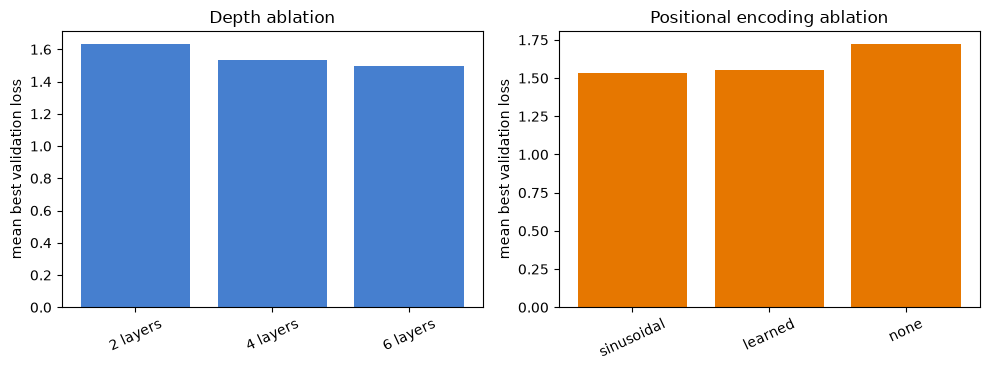

In [10]:
rows = list(csv.DictReader((ROOT / "outputs/ablations/results.csv").open(encoding="utf-8")))
grouped = defaultdict(list)
for row in rows:
    grouped[(row["group"], row["setting"])].append(float(row["best_val_loss"]))
for (group, setting), values in grouped.items():
    if group in {"depth", "position"}:
        mean = sum(values) / len(values)
        std = (sum((v - mean) ** 2 for v in values) / len(values)) ** 0.5
        print(f"{group:8s} {setting:14s} best val loss {mean:.4f} +/- {std:.4f} (n={len(values)})")

depth = {setting: sum(values) / len(values) for (group, setting), values in grouped.items() if group == "depth"}
position = {setting: sum(values) / len(values) for (group, setting), values in grouped.items() if group == "position"}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].bar(list(depth), list(depth.values()), color="#467fcf")
axes[0].set_title("Depth ablation"); axes[0].set_ylabel("mean best validation loss"); axes[0].tick_params(axis="x", rotation=25)
axes[1].bar(list(position), list(position.values()), color="#e67700")
axes[1].set_title("Positional encoding ablation"); axes[1].set_ylabel("mean best validation loss"); axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

## Final recording checklist

- [ ] 1 — show repository tree and point to `src/gpt.py` and `src/attention.py`.
- [ ] 2 — show the mask matrix and explain future-token weights become zero.
- [ ] 3 — show the complete `python -m pytest` result and exit code 0.
- [ ] 4 — show the configuration and exact `4,772,352` count.
- [ ] 5 — show the saved train/validation loss plot and explain the gap.
- [ ] 6 — show the fixed `ROMEO:` generation and seed.
- [ ] 7 — show the attention heatmap and read one local/long-range statistic.
- [ ] 8 — show `/docs` or `/model-info` and one inference request.
- [ ] 9 — show the measured ablation plot and state limitations.

### What not to say

Do not say that the notebook trained the final model, that the live checkpoint is present, or that the public `POST /generate` endpoint is unauthenticated unless the displayed output proves it. The notebook distinguishes saved evidence, optional local execution, and deployment reachability.